# HW10 Part 2: Exploratory and descriptive analysis
**Project F1: Moodle Activity, Marina Gorelikova**

Here we look at how students and teachers used Moodle from 2019 to 2026.

We count activity in active days. An active day is a day when a student did at least one thing in Moodle. We don't count events, because about 15% of the event rows are duplicates and a few students have a huge number of events.

All numbers are per student. We divide by the number of students in grades for that year, so students who never opened Moodle are also included.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../results/figures", exist_ok=True)   # folder for poster figures

years = [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

events_list = []
grades_list = []
calendar_list = []

for year in years:
    events_list.append(pd.read_parquet("../data/" + str(year) + "/events.parquet"))
    grades_list.append(pd.read_csv("../data/" + str(year) + "/grades.csv"))
    calendar_list.append(pd.read_csv("../data/" + str(year) + "/calendar.csv"))

events = pd.concat(events_list, ignore_index=True)
grades = pd.concat(grades_list, ignore_index=True)
calendar = pd.concat(calendar_list, ignore_index=True)
course_runs = pd.read_csv("../data/course_runs.csv")

print("events:", events.shape)
print("grades:", grades.shape)
print("calendar:", calendar.shape)
print("course_runs:", course_runs.shape)

/Users/marinagorelikova/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/marinagorelikova/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


events: (972372, 9)
grades: (945, 41)
calendar: (750, 5)
course_runs: (8, 9)


In [2]:
# Year in all tables (TCS_2019 -> 2019)
for df in [events, grades, calendar, course_runs]:
    df["year"] = df["course_run_id"].str[-4:].astype(int)

# Calendar date of each event (time is already in Tallinn time zone)
events["date"] = events["event_time"].dt.tz_localize(None).dt.normalize()

In [3]:
# Only students
students = events[events["actor_id"] != "T"].copy()

# Week of the semester: week 1 = first 7 days from the course start
start = pd.to_datetime(course_runs.set_index("year")["course_start_date"])
students["week"] = (students["date"] - students["year"].map(start)).dt.days // 7 + 1

In [4]:
# One row = one student active on one day
student_days = students[["year", "actor_id", "date", "week"]].drop_duplicates()

# Number of students in each year (from grades: includes students with no activity)
n_students = grades.groupby("year").size()

# Active days per week, divided by the number of students -> average per student
weekly = student_days.groupby(["week", "year"]).size().unstack()
weekly = weekly / n_students
weekly = weekly.loc[1:18]

weekly.round(2).head()

year,2019,2020,2021,2022,2023,2024,2025,2026
week,,,,,,,,
1,1.56,NaN,1.56,1.61,2.01,2.23,2.08,2.15
2,2.14,1.54,2.82,2.40,2.36,2.46,2.16,1.89
3,2.22,1.38,2.61,2.22,2.31,2.89,1.99,2.41
4,2.87,2.17,3.15,2.51,3.03,3.01,2.39,1.93
5,2.90,2.95,3.42,2.59,3.25,3.26,3.03,2.86


In [5]:
# Sanity check: log period vs course start, and weekly totals vs total active days per student
check = students.groupby("year")["date"].agg(["min", "max"])
check["course_start_date"] = course_runs.set_index("year")["course_start_date"]
check["median active days per student"] = student_days.groupby(["year", "actor_id"]).size().groupby("year").median()
check["sum of weekly averages (weeks 1-18)"] = weekly.sum().round(1)
check

,min,max,course_start_date,median active days per student,sum of weekly averages (weeks 1-18)
year,,,,,
2019,2019-02-11,2019-06-28,2019-02-11,49.0,49.7
2020,2020-02-19,2020-06-26,2020-02-10,58.0,55.5
2021,2021-02-10,2021-06-26,2021-02-08,63.5,58.7
2022,2022-02-07,2022-06-23,2022-02-07,52.5,48.9
2023,2023-02-06,2023-06-24,2023-02-06,55.5,53.4
2024,2024-02-12,2024-06-30,2024-02-12,56.0,58.7
2025,2025-02-10,2025-06-28,2025-02-10,50.0,50.3
2026,2026-02-09,2026-06-28,2026-02-09,52.0,49.2


In most years the logs start on the first day of the course. In 2020 they start 9 days later and in 2021 two days later. When we add up the weekly averages, we get almost the same number as the median of active days per student. So the weekly numbers look correct.

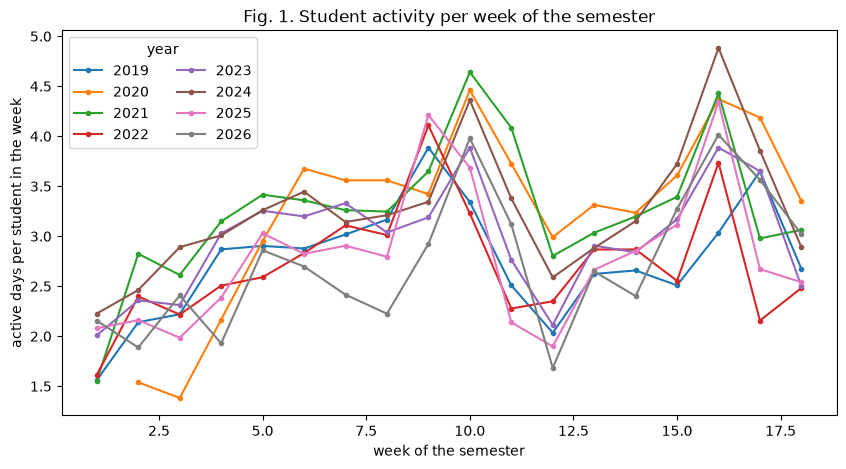

In [6]:
ax = weekly.plot(figsize=(10, 5), marker="o", markersize=3)
ax.set_title("Fig. 1. Student activity per week of the semester")
ax.set_xlabel("week of the semester")
ax.set_ylabel("active days per student in the week")
ax.legend(title="year", ncol=2)
plt.savefig("../results/figures/trends_fig1_weekly_activity.pdf", bbox_inches="tight")
plt.show()

Students are most active in week 9 or 10, when the first midterm is, and in week 16, when the exam is. Right after the midterm, in week 12, activity goes down a lot. At the start of the semester students use Moodle about 2 days a week, and later about 3.

The first weeks of 2020 are lower than other years, but this is because the logs start later. In 2024 students were the most active before the exam, almost 5 days a week. The midterm is not in the same week every year, so in the next figure we count weeks from the midterm to make years easier to compare.

## Weekly activity aligned to the first midterm
The midterm is not in the same week every year. Here we count weeks from the first midterm, so week 0 is the midterm week in every year. We also split the years by course format.

In [7]:
# Date of the first midterm in each year 
mid = calendar[calendar["activity_name"] == "midterm_attempt_1"].copy()
mid["midterm_date"] = pd.to_datetime(mid["start_time"].str[:10])
midterm = mid.groupby("year")["midterm_date"].min()

# Course format from our plan, next to delivery_mode from the data
FORMAT = {2019: "in-person", 2020: "remote", 2021: "remote", 2022: "hybrid",
          2023: "hybrid", 2024: "hybrid", 2025: "in-person", 2026: "in-person"}

info = course_runs.set_index("year")[["delivery_mode"]].copy()
info["format in our plan"] = info.index.map(FORMAT)
info["first midterm"] = midterm.dt.date
info["midterm week"] = (midterm - start).dt.days // 7 + 1
info

,delivery_mode,format in our plan,first midterm,midterm week
year,,,,
2019,in_person,in-person,2019-04-15,10
2020,remote,remote,2020-04-17,10
2021,remote,remote,2021-04-16,10
2022,hybrid,hybrid,2022-04-08,9
2023,hybrid,hybrid,2023-04-14,10
2024,hybrid,hybrid,2024-04-19,10
2025,in_person,in-person,2025-04-11,9
2026,in_person,in-person,2026-04-17,10


In [8]:
# Weeks from the first midterm: 0 = the 7 days starting on the midterm day, -1 = the week before
student_days["week_mid"] = (student_days["date"] - student_days["year"].map(midterm)).dt.days // 7

weekly_mid = student_days.groupby(["week_mid", "year"]).size().unstack()
weekly_mid = weekly_mid / n_students
weekly_mid = weekly_mid.loc[-8:7]

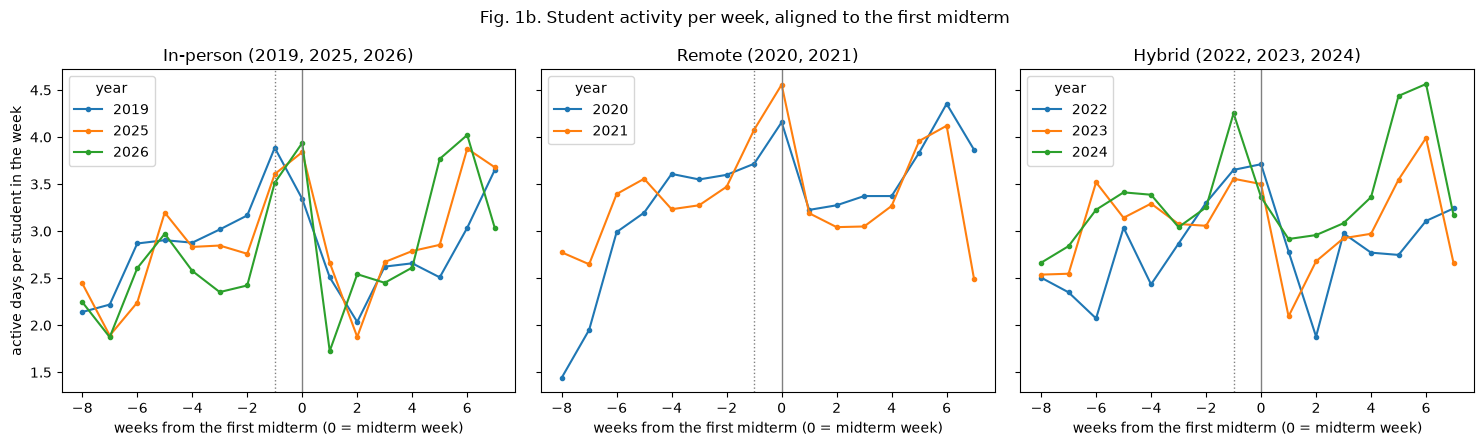

In [9]:
groups = {
    "In-person (2019, 2025, 2026)": [2019, 2025, 2026],
    "Remote (2020, 2021)": [2020, 2021],
    "Hybrid (2022, 2023, 2024)": [2022, 2023, 2024],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (title, group_years) in zip(axes, groups.items()):
    for y in group_years:
        ax.plot(weekly_mid.index, weekly_mid[y], marker="o", markersize=3, label=str(y))
    ax.axvline(0, color="gray", linewidth=1)                    # midterm week
    ax.axvline(-1, color="gray", linewidth=1, linestyle=":")    # prediction cutoff
    ax.set_title(title)
    ax.set_xlabel("weeks from the first midterm (0 = midterm week)")
    ax.legend(title="year")

axes[0].set_ylabel("active days per student in the week")
fig.suptitle("Fig. 1b. Student activity per week, aligned to the first midterm")
plt.tight_layout()
plt.savefig("../results/figures/trends_fig1_weekly_activity_by_format.pdf", bbox_inches="tight")
plt.show()

After we align the weeks to the first midterm, all years have the same shape. Activity grows until the midterm, drops a lot one or two weeks after it, and grows again before the exam.

The formats are different in the level of activity. Before the prediction cutoff, students in remote years used Moodle about 3 to 3.6 days a week, and in in-person years about 2 to 3 days. After the midterm, activity in remote years stayed around 3 days a week, but in in-person years it fell to about 2. In 2024 the peaks were the highest. 2022 jumps more than other years, but it also had the smallest group of students (83).

In 2019 the midterm was on a Monday, and in other years on a Friday, so the peak in 2019 is one week earlier.

This is important for the model: the level of activity before the cutoff is different in different years. A rule like "less than X active days means risk" learned on older years may not work on 2025 and 2026.

## Active days per student in the whole semester

In [10]:
# All students from grades (also those who never opened Moodle)
roster = grades[["year", "actor_id"]].drop_duplicates()

# Active days of each student in the whole semester
days = student_days.groupby(["year", "actor_id"]).size().rename("active_days").reset_index()

# Join: students without any activity get 0 active days
per_student = roster.merge(days, on=["year", "actor_id"], how="left")
per_student["active_days"] = per_student["active_days"].fillna(0)

# Summary table by year
summary = per_student.groupby("year")["active_days"].agg(["count", "median", "mean"])
summary["no activity"] = per_student["active_days"].eq(0).groupby(per_student["year"]).sum()
summary.insert(0, "format", summary.index.map(FORMAT))
summary.round(1)

,format,count,median,mean,no activity
year,,,,,
2019,in-person,114,49.0,50.0,0
2020,remote,102,57.0,56.8,3
2021,remote,142,62.5,60.2,2
2022,hybrid,83,52.0,49.9,1
2023,hybrid,106,55.5,55.2,0
2024,hybrid,119,56.0,60.5,0
2025,in-person,137,50.0,52.1,0
2026,in-person,142,52.0,51.3,1


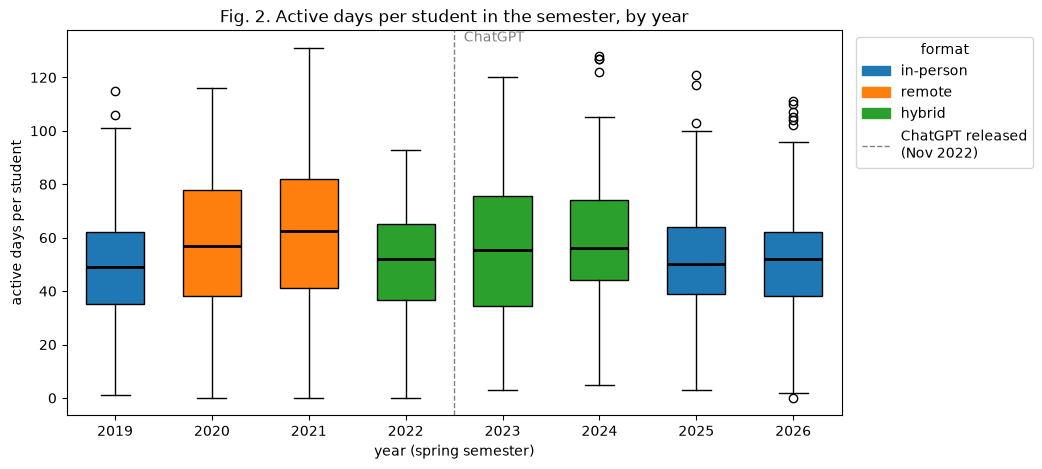

In [11]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

colors = {"in-person": "tab:blue", "remote": "tab:orange", "hybrid": "tab:green"}
data = [per_student.loc[per_student["year"] == y, "active_days"] for y in years]

fig, ax = plt.subplots(figsize=(10, 5))

# Each box stands at its year on the x axis (2019, 2020, ...)
box = ax.boxplot(data, positions=years, widths=0.6, patch_artist=True,
                 medianprops=dict(color="black", linewidth=2))
ax.set_xticks(years)

# Color of each box = course format of that year
for patch, y in zip(box["boxes"], years):
    patch.set_facecolor(colors[FORMAT[y]])

# Line between 2022 and 2023: ChatGPT appeared in November 2022
ax.axvline(2022.5, color="gray", linestyle="--", linewidth=1)
ax.text(2022.6, ax.get_ylim()[1], "ChatGPT", va="top", color="gray")

ax.set_title("Fig. 2. Active days per student in the semester, by year")
ax.set_xlabel("year (spring semester)")
ax.set_ylabel("active days per student")
legend_items = [Patch(color=c, label=f) for f, c in colors.items()]
legend_items.append(Line2D([0], [0], color="gray", linestyle="--", linewidth=1,
                           label="ChatGPT released\n(Nov 2022)"))
ax.legend(handles=legend_items, title="format", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.savefig("../results/figures/trends_fig2_active_days_by_year.pdf", bbox_inches="tight")
plt.show()

The median student was active on 49 to 62.5 days in the semester. Remote years were the highest (median 57 in 2020 and 62.5 in 2021), hybrid years were in the middle (52 to 56), and in-person years were the lowest (49 to 52).

The difference between years is small compared to the difference between students in the same year. The medians differ by about 13 days at most, but the middle half of students in one year can differ by 25 to 40 days. So individual students differ much more than years do.

ChatGPT was released in November 2022, after the spring semester of 2022, so 2023 is the first year when students could use it. We don't see a clear change after ChatGPT appeared: from 2022 to 2023 the median grew only by 3.5 days. The changes match the course format better.

Almost all students used Moodle. Only 0 to 3 students per year had no activity at all.

## Teacher activity
All teachers have the same code T in the data, so we can only look at teacher activity as a whole.

In [12]:
teachers = events[events["actor_id"] == "T"]

# Count distinct actions per day: the same action on the same resource on one day counts once.
# This does not depend on time precision (minutes in 2019-2023, seconds later) or on duplicate rows.
cols = ["year", "date", "event_context", "event_name"]
teacher_actions = teachers.drop_duplicates(subset=cols)

teacher = pd.DataFrame({
    "active days": teachers.groupby("year")["date"].nunique(),
    "actions": teacher_actions.groupby("year").size(),
})
teacher["actions per student"] = teacher["actions"] / n_students
teacher.insert(0, "format", teacher.index.map(FORMAT))
teacher.round(1)

,format,active days,actions,actions per student
year,,,,
2019,in-person,120,1792,15.7
2020,remote,118,2719,26.7
2021,remote,138,4397,31.0
2022,hybrid,134,3840,46.3
2023,hybrid,136,3460,32.6
2024,hybrid,131,3337,28.0
2025,in-person,135,3032,22.1
2026,in-person,131,2894,20.4


In [13]:
# How many teacher rows are exact duplicates (same time and same action) in each year?
exact_cols = ["course_run_id", "event_time", "event_context", "component", "event_name", "affected_actor_id"]
dup_check = pd.DataFrame({
    "all rows": teachers.groupby("year").size(),
    "after removing exact duplicates": teachers.drop_duplicates(subset=exact_cols).groupby("year").size(),
})
dup_check["removed, %"] = (1 - dup_check["after removing exact duplicates"] / dup_check["all rows"]) * 100
dup_check.round(1)

,all rows,after removing exact duplicates,"removed, %"
year,,,
2019,19036,14458,24.0
2020,26923,18043,33.0
2021,33469,20300,39.3
2022,28201,13955,50.5
2023,32545,20496,37.0
2024,35821,32826,8.4
2025,32737,28600,12.6
2026,30550,24667,19.3


In 2019 to 2023 the time in the logs is saved only to the minute, so many different teacher actions look like duplicates. When we removed duplicate rows, we removed 24 to 50% of teacher rows in 2019 to 2023, but only 8 to 19% in 2024 to 2026. So we can't compare raw or deduplicated action counts between these years. Instead we count distinct actions per day, which does not depend on the time precision.

In [14]:
# Check: are there any message or chat events in the course logs?
is_message = (events["event_name"].str.contains("message|chat", case=False)
              | events["component"].str.contains("message|chat", case=False))
print("message/chat events:", is_message.sum())

message/chat events: 0


There are no message or chat events in the data. Private messages are not part of the course logs.

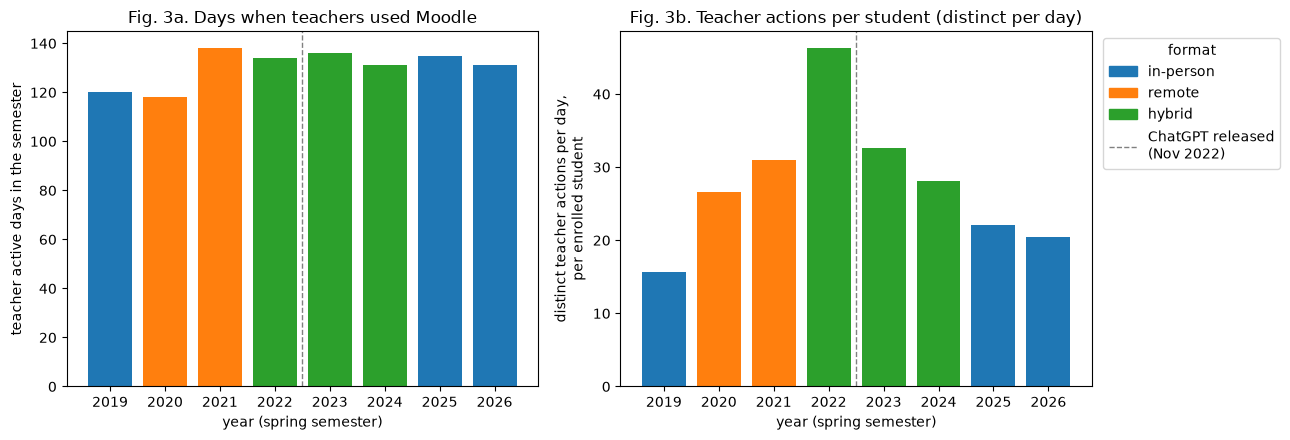

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bar_colors = [colors[FORMAT[y]] for y in teacher.index]

axes[0].bar(teacher.index, teacher["active days"], color=bar_colors)
axes[0].set_title("Fig. 3a. Days when teachers used Moodle")
axes[0].set_ylabel("teacher active days in the semester")

axes[1].bar(teacher.index, teacher["actions per student"], color=bar_colors)
axes[1].set_title("Fig. 3b. Teacher actions per student (distinct per day)")
axes[1].set_ylabel("distinct teacher actions per day,\nper enrolled student")

for ax in axes:
    ax.set_xticks(years)
    ax.set_xlabel("year (spring semester)")
    ax.axvline(2022.5, color="gray", linestyle="--", linewidth=1)

axes[1].legend(handles=legend_items, title="format", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("../results/figures/trends_fig3_teacher_activity.pdf", bbox_inches="tight")
plt.show()

Teachers used Moodle almost every day in all years, on 118 to 138 days in the semester. 2020 is a bit lower because the logs start 9 days after the course start.

To compare teacher work between years, we count distinct actions per day. We don't use raw event counts, because in 2019 to 2023 the time is saved only to the minute, and many different actions look like duplicates.

Teacher activity changed a lot. In 2019 there were about 16 distinct actions per student. In the remote years it grew to 27 and 31, and in 2022 it was the highest, 46. After that it went down every year, to about 22 in 2025 and 20 in 2026. This is still higher than in 2019, the other in-person year. It looks like teachers kept part of their online work after COVID.

The high value in 2022 is partly because 2022 had the smallest group of students (83). Some teacher work, like uploading materials or creating quizzes, does not depend on the number of students. In total numbers, 2021 had the most teacher actions.

Teacher activity goes down from 2023, the first year with ChatGPT. In 2023 and 2024 the course was still hybrid, so this drop is not because of the course format. But per student numbers are high in 2022 because of the small group, and in total numbers the drop is small: from 3840 actions in 2022 to 3337 in 2024. Teacher activity keeps going down in 2025 and 2026, when the course went back to in-person teaching (3032 and 2894 actions). Teachers could also reuse the course materials from earlier years. Teachers may also use AI to prepare materials, but Moodle logs only show actions inside Moodle, not how much time teachers spent on their work. So we can't say if AI had any effect.

Our data has some limits. All teachers have the same code T, so we don't know if the changes come from more work or from more teachers.

Private messages between students and teachers are not in the course logs, so this communication is not included. Students could also contact teachers by email or in other apps.

## What students use in Moodle
Moodle tools changed between years (for example, homework was sometimes a Quiz and sometimes an Assignment), so we join components into groups, the same groups as in the data preparation part.

In [16]:
# Component groups: we use the same dictionary as in the data preparation part (src/prepare.py)
import sys
sys.path.append("..")                     # so Python can find the src folder from hw10/
from src.prepare import COMPONENT_GROUPS

GROUPS = dict(COMPONENT_GROUPS)
GROUPS["System"] = "course page"          # course page views: only for this descriptive part

students["group"] = students["component"].map(GROUPS).fillna("other")

# Check: every component with its group and number of student events
students.groupby(["group", "component"]).size().sort_values(ascending=False)

group        component              
homework     Quiz                       234809
course page  System                     218018
homework     Assignment                  74162
materials    URL                         63023
grades       User report                 40706
materials    File                        29552
lectures     BigBlueButton               28505
forum        Forum                       22639
homework     File submissions             6348
             Online text submissions      6348
lectures     BigBlueButtonBN              4762
other        Choice                       2166
grades       Overview report              1888
other        Feedback                      128
             Submission comments            33
             UT custom functions             3
dtype: int64

In [17]:
# What students do in "System": the 10 most common event names
students.loc[students["component"] == "System", "event_name"].value_counts().head(10)

event_name
Course viewed                         179125
Course user report viewed              31810
User graded                             5404
Course activity completion updated       609
User profile viewed                      298
Course module instance list viewed       266
User list viewed                         264
Grade item updated                       242
Name: count, dtype: int64

In [18]:
# One row = one student used one group on one day
group_days = students[["year", "actor_id", "date", "group"]].drop_duplicates()

# Days per student on which the student used each group
usage = group_days.groupby(["year", "group"]).size().unstack().div(n_students, axis=0).fillna(0)

# Share of students who used each group at least once (%)
users = students[["year", "actor_id", "group"]].drop_duplicates()
reach = users.groupby(["year", "group"]).size().unstack().div(n_students, axis=0).fillna(0) * 100

print("Days per student using each group:")
display(usage.round(1))
print("Share of students who used the group at least once, %:")
display(reach.round(0))

Days per student using each group:


group,course page,forum,grades,homework,lectures,materials,other
year,,,,,,,
2019,43.4,2.3,23.6,34.2,0.0,15.9,0.1
2020,53.1,8.6,19.2,42.7,11.1,20.9,0.1
2021,57.2,12.6,17.2,42.1,20.0,24.0,2.1
2022,46.8,10.0,15.9,34.3,13.2,23.1,3.7
2023,52.2,7.7,17.4,36.8,10.1,25.0,0.0
2024,55.8,11.9,18.5,38.0,8.4,26.6,0.0
2025,47.6,11.1,21.1,30.0,6.6,20.5,0.0
2026,46.0,9.8,20.4,28.6,6.4,18.9,0.0


Share of students who used the group at least once, %:


group,course page,forum,grades,homework,lectures,materials,other
year,,,,,,,
2019,100.0,62.0,90.0,99.0,0.0,98.0,8.0
2020,97.0,88.0,79.0,97.0,93.0,97.0,10.0
2021,99.0,89.0,73.0,97.0,96.0,97.0,92.0
2022,99.0,84.0,83.0,96.0,95.0,98.0,94.0
2023,100.0,85.0,82.0,100.0,95.0,98.0,0.0
2024,100.0,94.0,82.0,100.0,96.0,100.0,0.0
2025,100.0,94.0,85.0,99.0,89.0,99.0,1.0
2026,99.0,92.0,85.0,98.0,87.0,99.0,3.0


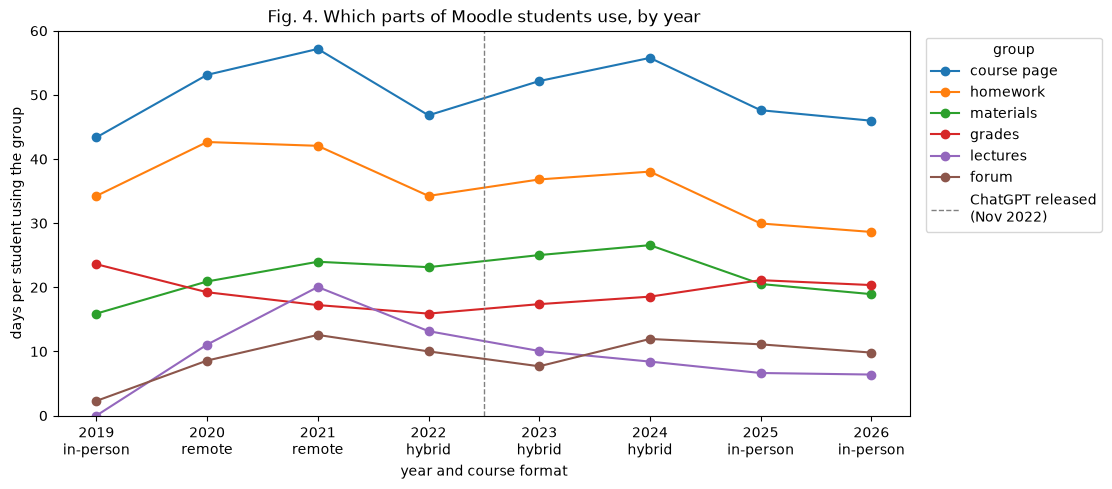

In [19]:
plot_groups = ["course page", "homework", "materials", "grades", "lectures", "forum"]

fig, ax = plt.subplots(figsize=(11, 5))
for g in plot_groups:
    ax.plot(usage.index, usage[g], marker="o", label=g)

ax.axvline(2022.5, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(years)
ax.set_xticklabels([f"{y}\n{FORMAT[y]}" for y in years])
ax.set_ylim(bottom=0)
ax.set_title("Fig. 4. Which parts of Moodle students use, by year")
ax.set_xlabel("year and course format")
ax.set_ylabel("days per student using the group")

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color="gray", linestyle="--", linewidth=1))
labels.append("ChatGPT released\n(Nov 2022)")
ax.legend(handles, labels, title="group", loc="upper left", bbox_to_anchor=(1.01, 1))

plt.savefig("../results/figures/trends_fig4_groups_by_year.pdf", bbox_inches="tight")
plt.show()

In [20]:
# ChatGPT check inside one format: 2022 (hybrid, before ChatGPT) vs 2023-2024 (hybrid, after)
hybrid = pd.DataFrame({
    "2022 (before)": usage.loc[2022, plot_groups],
    "2023-2024 (after)": usage.loc[[2023, 2024], plot_groups].mean(),
})
hybrid["change, days"] = hybrid["2023-2024 (after)"] - hybrid["2022 (before)"]
hybrid.round(1)

,2022 (before),2023-2024 (after),"change, days"
group,,,
course page,46.8,54.0,7.1
homework,34.3,37.4,3.2
materials,23.1,25.8,2.7
grades,15.9,18.0,2.1
lectures,13.2,9.2,-3.9
forum,10.0,9.8,-0.2


Students use the course page and homework the most. Homework was highest in the remote years (about 43 days per student) and lowest in 2025 and 2026 (about 29 to 30 days), even lower than in 2019, the other in-person year.

Online lectures (lectures) appeared in 2020. In 2021 students used them on about 20 days, and after that less every year, about 6 days in 2025 and 2026. But even in these in-person years 87 to 89% of students used them at least once. The forum was used by only 62% of students in 2019, but by 84 to 94% from 2021. Materials were also used more after 2019. It looks like COVID moved a part of learning into Moodle, and a lot of it stayed after students came back to classrooms.

Students checked their grades (grades) more often in the in-person years (about 20 to 24 days) than in the remote and hybrid years (about 16 to 19 days).

To check ChatGPT, we compare 2022 with 2023 and 2024, because all three years were hybrid. After ChatGPT appeared, students used homework and materials a bit more, not less (about 3 days more). They also opened the course page more often (about 7 days more). Online lectures went down, but they were going down already from 2021. So we don't see a change in Moodle use after ChatGPT. But Moodle logs only show that a student opened or submitted homework, not how the homework was done.

## Main findings

1. **The semester has the same rhythm every year.** Activity grows before the midterm, drops right after it, and grows again before the exam. Students study in bursts before deadlines, not evenly.

2. **Students differ more than years do.** The median student was active on 49 days in in-person years and up to 62.5 days in remote years, so years differ by about 13 days. But in one year, the middle half of students differ by 25 to 40 days.

3. **COVID moved a part of learning into Moodle, and a lot of it stayed.** Even in the in-person years 2025 and 2026, 87 to 89% of students used online lectures, and 84 to 94% used the forum (only 62% in 2019). Teachers also stayed more active than in 2019.

4. **We don't see a change in Moodle use after ChatGPT.** When we compare the hybrid years 2022 and 2023 to 2024, students used homework and materials a bit more, not less. But the logs only show that homework was opened or submitted, not how it was done.

5. **For the model:** the level of activity before the cutoff is different in different years, so we expected a fixed rule like "15 active days or less" to work worse in the in-person years 2025 and 2026. Denis checked this in the generalization part. Comparing a student with their own year did not help, and the rule marked wrong students about as often as in older years. The bigger problem is that results change a lot from year to year, because only 10 to 28 students fail in one year.

**Limits:** we only see what happens inside Moodle, not lectures in the classroom, emails or other apps. All teachers have the same code, and the course format changed at the same time as ChatGPT appeared, so we can show correlations, not causes.

## Task 3b

Without our result, a teacher learns which students have problems only at the midterm, when it is often too late to help. With our result, the teacher gets a list of students at risk one week before the midterm, using only data that Moodle already has.

We tried three ways to make this list: a simple rule, logistic regression and random forest. For the teacher, the simple rule works best. In 2025 and 2026 there were 279 students, and 45 of them failed. The rule "active on 15 days or less before the cutoff" marked 92 students. It found 33 of the 45 students who failed (recall 0.73), and about 1 of 3 marked students really failed (precision 0.36). This meets the goal we set in HW7. If the teacher picked students at random, only about 1 of 6 would fail, so the rule is more than twice as good as guessing. The two models were right more often when they marked a student (precision 0.59 and 0.55), but they found less than half of the students who failed (19 and 17 of 45). Missing a student who needs help is worse than one extra message, so the rule is the better choice. It is also easy to explain to teachers and students.

Is it good enough to rely on? For a friendly email or an offer of help, we think yes. Such a message costs almost nothing. But the teacher should know three things.

First, the rule marks about one third of the course, and about 2 of 3 marked students will pass. So the message must not sound like a warning or a label.

Second, it misses 12 of 45 students who failed. These students used Moodle normally but failed for other reasons, so the list does not replace the teacher's own attention.

Third, the result changes a lot between years. In 2026 the rule found 15 of 17 failed students, but in 2025 only 18 of 28. In one year only 10 to 28 students fail, so a few students change the numbers a lot. We also tried to compare each student with their own year instead of using a fixed number of days, but it did not help. So the teacher should check how well the rule worked after every year.

So the result is useful as an early hint for the teacher, but not as a reason to treat a student differently or to give a grade.

## Task 4a

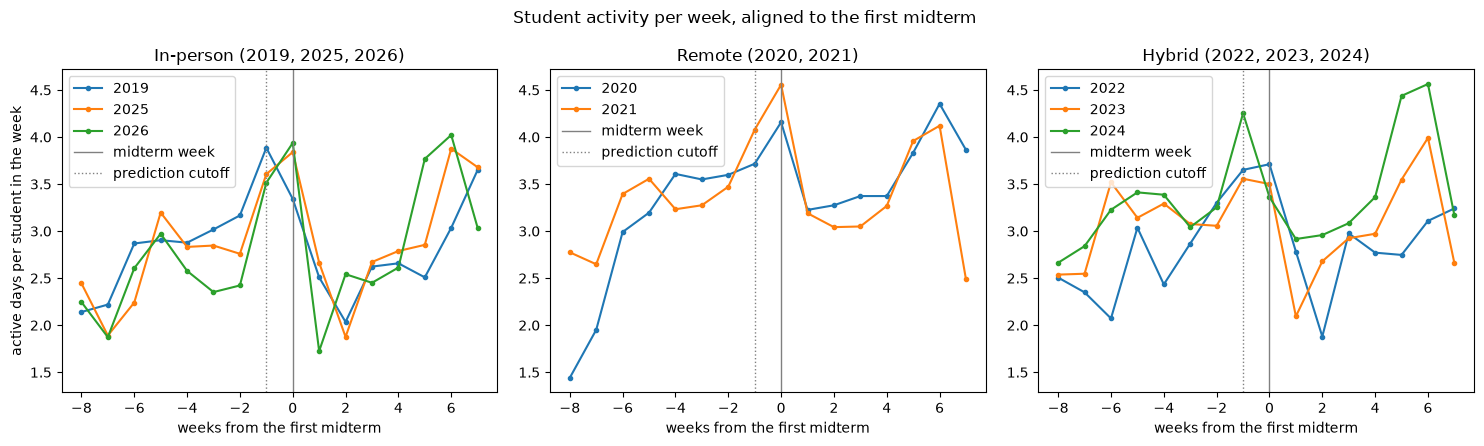

In [21]:
# Task 4a, graph 1: student activity per week, aligned to the first midterm.
# This cell works on its own: it loads the raw data and makes the figure.
import pandas as pd
import matplotlib.pyplot as plt

years = [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
events = pd.concat([pd.read_parquet("../data/" + str(y) + "/events.parquet") for y in years], ignore_index=True)
grades = pd.concat([pd.read_csv("../data/" + str(y) + "/grades.csv") for y in years], ignore_index=True)
calendar = pd.concat([pd.read_csv("../data/" + str(y) + "/calendar.csv") for y in years], ignore_index=True)
for table in [events, grades, calendar]:
    table["year"] = table["course_run_id"].str[-4:].astype(int)

# One row = one student active on one day
events["date"] = events["event_time"].dt.tz_localize(None).dt.normalize()
student_days = events.loc[events["actor_id"] != "T", ["year", "actor_id", "date"]].drop_duplicates()

# Weeks from the first midterm (0 = midterm week)
mid = calendar[calendar["activity_name"] == "midterm_attempt_1"]
midterm = pd.to_datetime(mid["start_time"].str[:10]).groupby(mid["year"]).min()
student_days["week_mid"] = (student_days["date"] - student_days["year"].map(midterm)).dt.days // 7

# Average active days per student in each week
n_students = grades.groupby("year").size()
weekly_mid = student_days.groupby(["week_mid", "year"]).size().unstack() / n_students
weekly_mid = weekly_mid.loc[-8:7]

groups = {
    "In-person (2019, 2025, 2026)": [2019, 2025, 2026],
    "Remote (2020, 2021)": [2020, 2021],
    "Hybrid (2022, 2023, 2024)": [2022, 2023, 2024],
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (title, group_years) in zip(axes, groups.items()):
    for y in group_years:
        ax.plot(weekly_mid.index, weekly_mid[y], marker="o", markersize=3, label=str(y))
    ax.axvline(0, color="gray", linewidth=1, label="midterm week")
    ax.axvline(-1, color="gray", linewidth=1, linestyle=":", label="prediction cutoff")
    ax.set_title(title)
    ax.set_xlabel("weeks from the first midterm")
    ax.tick_params(labelleft=True)                          
    ax.legend()
axes[0].set_ylabel("active days per student in the week")
fig.suptitle("Student activity per week, aligned to the first midterm")
plt.tight_layout()
plt.show()

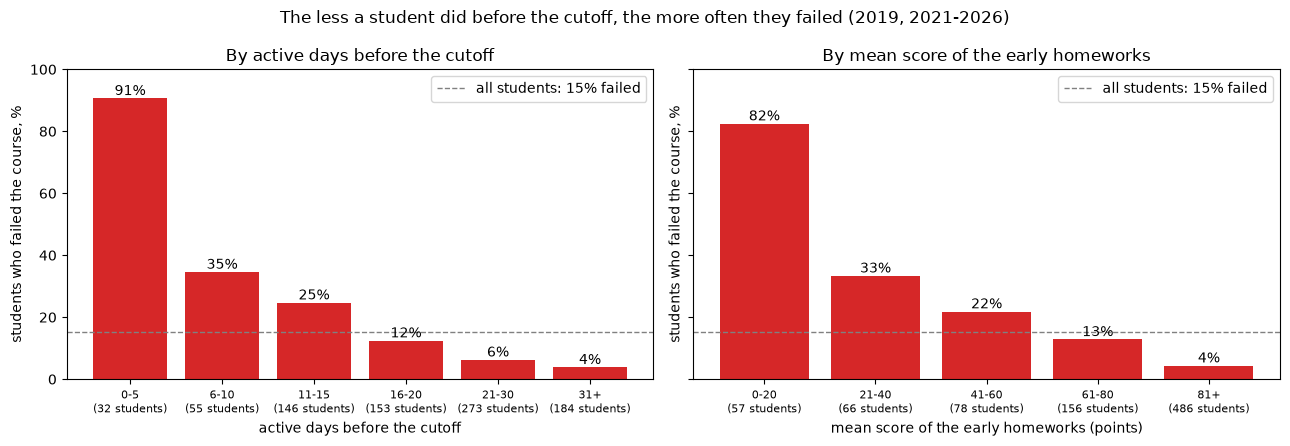

In [22]:
# Task 4a, graph 2: share of students who failed, by Moodle activity and early homework before the cutoff.
# This cell works on its own: it builds the feature table with the shared function from src/prepare.py.
import sys
sys.path.append("..")
from src.prepare import build_features

features_table = build_features("../data")

# Groups by active days and by early homework score
days_groups = pd.cut(features_table["active_days"], [-1, 5, 10, 15, 20, 30, 100],
                     labels=["0-5", "6-10", "11-15", "16-20", "21-30", "31+"])
hw_groups = pd.cut(features_table["hw_early_mean"], [-1, 20, 40, 60, 80, 200],
                   labels=["0-20", "21-40", "41-60", "61-80", "81+"])

# Share of failed students (%) and number of students in each group
fail_by_days = features_table.groupby(days_groups, observed=True)["fail"].agg(["mean", "size"])
fail_by_hw = features_table.groupby(hw_groups, observed=True)["fail"].agg(["mean", "size"])
fail_by_days["mean"] = fail_by_days["mean"] * 100
fail_by_hw["mean"] = fail_by_hw["mean"] * 100
fail_all = features_table["fail"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
panels = [(axes[0], fail_by_days, "By active days before the cutoff", "active days before the cutoff"),
          (axes[1], fail_by_hw, "By mean score of the early homeworks", "mean score of the early homeworks (points)")]
for ax, table, title, x_label in panels:
    labels = [f"{group}\n({n} students)" for group, n in zip(table.index, table["size"])]
    bars = ax.bar(labels, table["mean"], color="tab:red")
    ax.bar_label(bars, fmt="%.0f%%")
    ax.axhline(fail_all, color="gray", linestyle="--", linewidth=1,
               label=f"all students: {fail_all:.0f}% failed")
    ax.legend(loc="upper right")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.tick_params(axis="x", labelsize=8, labelleft=True)
    ax.set_ylabel("students who failed the course, %")
axes[0].set_ylim(0, 100)
fig.suptitle("The less a student did before the cutoff, the more often they failed (2019, 2021-2026)")
plt.tight_layout()
plt.show()

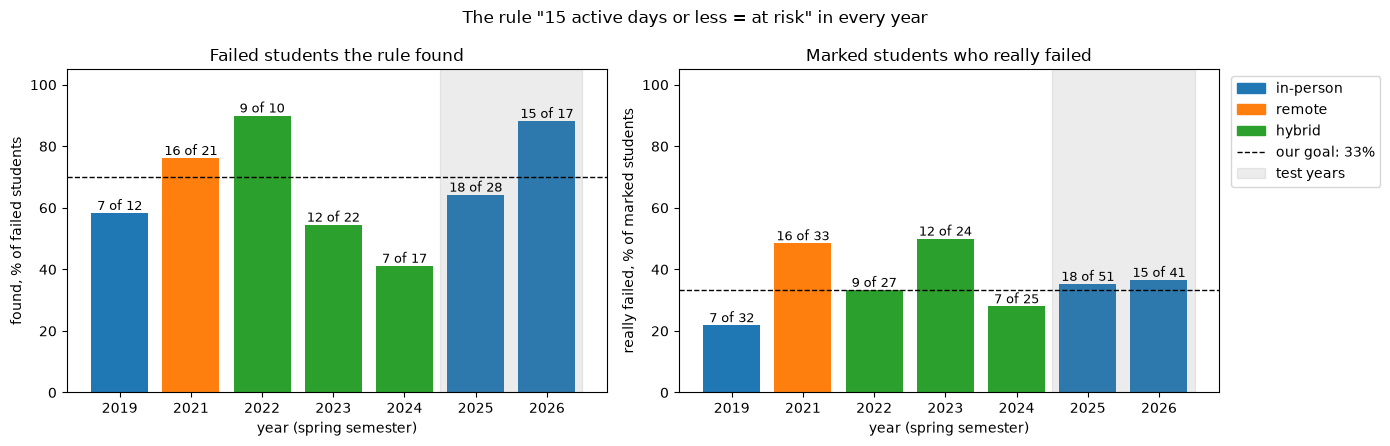

In [23]:
# Task 4a, graph 3: the rule "15 active days or less = at risk" in every year.
# This cell works on its own: it builds the feature table with the shared function from src/prepare.py.
import sys
sys.path.append("..")
from matplotlib.patches import Patch
from src.prepare import build_features

rule_table = build_features("../data")

rows = []
for year, year_students in rule_table.groupby("year"):
    marked = year_students["active_days"] <= 15
    failed = year_students["fail"] == 1
    rows.append({"year": year, "failed": failed.sum(), "marked": marked.sum(),
                 "found": (marked & failed).sum()})
rule_years = pd.DataFrame(rows).set_index("year")
rule_years["recall"] = rule_years["found"] / rule_years["failed"] * 100
rule_years["precision"] = rule_years["found"] / rule_years["marked"] * 100

year_format = {2019: "in-person", 2021: "remote", 2022: "hybrid", 2023: "hybrid",
               2024: "hybrid", 2025: "in-person", 2026: "in-person"}
format_colors = {"in-person": "tab:blue", "remote": "tab:orange", "hybrid": "tab:green"}
bar_colors = [format_colors[year_format[y]] for y in rule_years.index]
year_labels = [str(y) for y in rule_years.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
panels = [(axes[0], "recall", "failed", 70,
           "Failed students the rule found", "found, % of failed students"),
          (axes[1], "precision", "marked", 100 / 3,
           "Marked students who really failed", "really failed, % of marked students")]
for ax, measure, total, goal, title, y_label in panels:
    bars = ax.bar(year_labels, rule_years[measure], color=bar_colors)
    ax.bar_label(bars, labels=[f"{f} of {t}" for f, t in zip(rule_years["found"], rule_years[total])], fontsize=9)
    ax.axhline(goal, color="black", linestyle="--", linewidth=1, label=f"our goal: {goal:.0f}%")
    ax.axvspan(4.5, 6.5, color="gray", alpha=0.15, label="test years")
    ax.set_ylim(0, 105)
    ax.set_title(title)
    ax.set_xlabel("year (spring semester)")
    ax.set_ylabel(y_label)

legend_items = [Patch(color=c, label=f) for f, c in format_colors.items()]
legend_items += axes[1].get_legend_handles_labels()[0]
axes[1].legend(handles=legend_items, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle('The rule "15 active days or less = at risk" in every year')
plt.tight_layout()
plt.show()

**Graph 1 (student activity per week):** In every year students are most active right before the midterm and the exam, but in remote years they used Moodle more often than in in-person years, so the same number of active days can mean different things in different years.

**Graph 2 (share of students who failed, from the data preparation part):** The fewer days a student used Moodle before the cutoff and the lower the early homework score, the more often the student failed (91% with 0 to 5 active days, only 4% with more than 30), but most students are in the middle groups, where the result is mixed, so some students will be marked wrongly.

**Graph 3 (the simple rule in every year):** The rule "15 active days or less" meets our goal for 2025 and 2026 together, but the results change a lot from year to year (it found 88% of the failed students in 2026 but only 64% in 2025), so one good number for a new year is not a promise.

## Task 4b

# Project F1: Moodle Activity

**Longitudinal Changes in Moodle Activity and Their Predictive Power for Student Results**

Authors: Marina Gorelikova, Denis Artemjev, Ander Hinn

Topic proposed by Reimo Palm (University of Tartu). LTAT.02.002 Introduction to Data Science, autumn 2026.

## Motivation

We use Moodle logs of the course Theoretical Computer Science (University of Tartu) from the spring semesters 2019 to 2026. In these years teaching changed a lot. In 2020 and 2021 the course was remote because of COVID, then hybrid, and from 2025 in-person again. At the end of 2022 ChatGPT appeared. This makes the data a natural experiment, we can see how students and teachers used Moodle before, during and after these changes.

About 15% of students fail the course or don't come to the exam. If teachers could see early which students are at risk, they could offer help in time.

## Goals

1. Describe how student and teacher activity in Moodle changed from 2019 to 2026.
2. Predict one week before the first midterm which students will fail the course, so that teachers have time to help them.
3. Check if a model trained on older years (2019, 2021 to 2024) still works on new years (2025 and 2026).

## What is in which file

| File | What it does |
|---|---|
| `src/prepare.py` | Shared code. `build_features()` builds the table that the models use: one row is one student in one year, with the target and 14 features. Only data from before the cutoff (one week before the first midterm) is used. |
| `hw10/01_data_prep_denis.ipynb` | Data preparation: how the data was cleaned and which features were made. |
| `hw10/02_trends_marina.ipynb` | Goal 1: how student and teacher activity changed from 2019 to 2026. |
| `hw10/03_models_ander.ipynb` | Goal 2: baseline rule and models that predict who will fail. |
| `hw10/04_generalization_denis.ipynb` | Goal 3: how well the rule and the models work on 2025 and 2026, each year on its own. |
| `results/figures/` | Figures as PDF files. The first word of the file name shows which notebook made it: `prep_` (data preparation), `trends_` (trends), `gen_` (new years). |
| `requirements.txt` | Python packages needed to run the notebooks. |
| `IDS2026_HW07.ipynb` | Homework 7: business understanding and first look at the data. |

## Data

The data is not in this repository, because it is about real students. The logs are pseudonymised, but we still don't publish them. The dataset was given to the students of the course by Reimo Palm (University of Tartu). Anyone who has access to it can repeat the analysis. Put the data into a folder `data/` in the root of the repository like this:

```
data/
  2019/events.parquet, grades.csv, calendar.csv
  2020/...
  ...
  2026/...
  course_runs.csv
```

The folder `data/` is in `.gitignore`, so it is never uploaded to GitHub.

## How to repeat the analysis

1. Clone the repository:

   ```
   git clone https://github.com/anderhinn/Project-F1-Moodle_Activity.git
   ```

2. Install the packages (Python 3.11):

   ```
   pip install -r requirements.txt
   ```

3. Put the data into the `data/` folder as shown above.

4. Open the notebooks in the `hw10/` folder and run them in this order, each with Restart & Run All: `01_data_prep_denis.ipynb`, `02_trends_marina.ipynb`, `03_models_ander.ipynb`, `04_generalization_denis.ipynb`. The figures are saved to `results/figures/`.

If `read_parquet` gives an error, check that `pyarrow` is installed. With NumPy 1.x you need `pyarrow` older than version 18.